# Add to database

In [3]:
import sqlite3
import csv

# Connect to your SQLite database
conn = sqlite3.connect("intrep_crystal_xrd.db")
cursor = conn.cursor()

structure_csv = "interp_metadata.csv"

# Load the CSV
with open(structure_csv, newline='') as csvfile:
    reader = csv.DictReader(csvfile)
    for row in reader:
        # Create the table once before the loop
        cursor.execute("""
            CREATE TABLE IF NOT EXISTS Structures (
                structure_id,
                source,
                generation_commit,
                extinction_group,
                crystal_system,
                space_group,
                composition,
                lattice_a,
                lattice_b,
                lattice_c,
                alpha,
                beta,
                gamma,
                atom_sites_json
            )
        """)

        # Then inside the loop, use only INSERT INTO
        cursor.execute("""
            INSERT INTO Structures (
                structure_id, source, generation_commit, extinction_group, crystal_system, 
                space_group, composition, lattice_a, lattice_b, lattice_c,
                alpha, beta, gamma, atom_sites_json
            ) VALUES ( ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
        """, (  row["structure_id"],
                row["source"],
                #row["source_id"],
                row["generation_commit"],
                #row["extinction_class"],
                int(row["extinction_group"]),
                row["crystal_system"],
                int(row["space_group"]),
                row["composition"],
                float(row["lattice_a"]),
                float(row["lattice_b"]),
                float(row["lattice_c"]),
                float(row["alpha"]),
                float(row["beta"]),
                float(row["gamma"]),
                #row["wyckoff_positions"],
                row["atoms"]))
        
# Commit and close
conn.commit()
conn.close()

print("All structure rows (with space group) loaded into the database successfully!")


All structure rows (with space group) loaded into the database successfully!


 # Verify upload

In [1]:
import sqlite3
import csv

# Connect to your database
conn = sqlite3.connect("intrep_crystal_xrd.db")
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM Structures")
count = cursor.fetchone()[0]
print(f"Number of rows in table: {count}")

Number of rows in table: 1000


# Check first entry

In [1]:
import sqlite3

# Connect to your database
conn = sqlite3.connect("intrep_crystal_xrd.db")
cursor = conn.cursor()

# Example query: select everything
cursor.execute("SELECT * FROM Structures")

# Fetch all rows (you can also use fetchone() or fetchmany())
rows = cursor.fetchall()

# Optional: get column names
columns = [description[0] for description in cursor.description]

# Print nicely
for row in rows:
    record = dict(zip(columns, row))
    print(record)
    break

# Close connection
conn.close()


{'structure_id': '331be1ef-d48c-41e1-8479-451d0912be8c', 'source': 'PyXtal', 'generation_commit': '3e5b6cb27ee263b875831c6ddf53994b0f323cb1', 'extinction_group': 1, 'crystal_system': 'Monoclinic', 'space_group': 6, 'composition': 'Ir2Sc2Yb2', 'lattice_a': 6.2824886330621945, 'lattice_b': 4.79225379515856, 'lattice_c': 5.521027253930496, 'alpha': 90.0, 'beta': 100.75613636611877, 'gamma': 90.0, 'atom_sites_json': "[{'symbol': 'Sc', 'position': array([0.92383867, 0.24375713, 0.65795994])}, {'symbol': 'Sc', 'position': array([0.92383867, 0.75624287, 0.65795994])}, {'symbol': 'Yb', 'position': array([0.3819144 , 0.        , 0.71845362])}, {'symbol': 'Yb', 'position': array([9.72797476e-02, 8.15776052e-34, 5.88539094e-02])}, {'symbol': 'Ir', 'position': array([0.52261759, 0.5       , 0.2992619 ])}, {'symbol': 'Ir', 'position': array([1.07664725e-01, 2.46901921e-33, 3.84604954e-01])}]"}


# Check entry using HDF5 index

In [11]:
import csv

hdf5_to_structure = {}

with open("interp_metadata_clean.csv", newline="") as f:
    reader = csv.DictReader(
        row for row in f if not row.lstrip().startswith("#")
    )
    for row in reader:
        hdf5_to_structure[int(row["hdf5_index"])] = row["structure_id"]

print(hdf5_to_structure[1])

c39d7883-927b-470f-8035-34ee71681b8a


# Extract all metadata

In [12]:
import sqlite3

conn = sqlite3.connect("intrep_crystal_xrd.db")
cursor = conn.cursor()

cursor.execute("""
    SELECT *
    FROM Structures
    WHERE structure_id = ?
""", (hdf5_to_structure[85],))

row = cursor.fetchone()
conn.close()

print(row)

('b41d0516-a5fd-4785-adc2-5b5257048df9', 'PyXtal', '3e5b6cb27ee263b875831c6ddf53994b0f323cb1', 7, 'Orthorhombic', 25, 'Ho2Ti2', 4.1452399577988395, 5.501697793870185, 5.187452317834676, 90.0, 90.0, 90.0, "[{'symbol': 'Ti', 'position': array([0.        , 0.        , 0.64227006])}, {'symbol': 'Ti', 'position': array([0.5       , 0.5       , 0.32358813])}, {'symbol': 'Ho', 'position': array([0.       , 0.5      , 0.4588281])}, {'symbol': 'Ho', 'position': array([0.5       , 0.        , 0.98312578])}]")


In [13]:
def generate_diffraction_pattern_helper(spacegroup_number, unit_cell, wavelength, twotheta_min, twotheta_max, twothstep, u, v, w, peak_scale=1000):
    """
    Generate a diffraction pattern for a given space group and unit cell.

    Parameters:
        spacegroup_number (int): Space group number.
        unit_cell (tuple): Unit cell parameters (a, b, c, alpha, beta, gamma).
        wavelength (float): Wavelength of the X-ray beam.
        twotheta_min (float): Minimum 2-theta value.
        twotheta_max (float): Maximum 2-theta value.
        twothstep (float): Step size for 2-theta.
        u, v, w (float): Peak shape parameters.
        peak_scale (float): Scale factor for peak intensity.

    Returns:
        tuple: (twotheta, I) where `twotheta` is an array of 2-theta values and `I` is the corresponding intensity array.
    """
    # Create symmetry object
    symmetry = crystal.symmetry(unit_cell=unit_cell, space_group=spacegroup_number)

    # Calculate d-spacing range
    d_max = twotheta_to_d(twotheta_min, wavelength=wavelength)
    d_min = twotheta_to_d(twotheta_max, wavelength=wavelength)

    # Build Miller set and get allowed reflections
    miller_set = symmetry.build_miller_set(anomalous_flag=False, d_min=d_min, d_max=d_max)
    allowed_reflections = miller_set.indices()
    uc = symmetry.unit_cell()

    # Initialize 2-theta and intensity arrays
    twotheta = np.arange(twotheta_min, twotheta_max, twothstep)
    I = np.zeros(len(twotheta))

    # Calculate intensity for each allowed reflection
    for hkl in allowed_reflections:
        d_spacing = uc.d(hkl)
        twotheta_center = 2 * np.arcsin(wavelength / (2 * d_spacing)) * 180 / np.pi
        ps=np.random.uniform(5, peak_scale)
        peak = Peak(twotheta_center, u, v, w, ps, hkl=hkl, shape="Gaussian", eta=0)
        I += peak(twotheta)

    # Apply Lorentz correction
    lorentz = 1 / (np.sin(np.radians(twotheta)) * np.sin(np.radians(twotheta / 2)))
    I *= lorentz

    # Normalize intensity
    I = 1000 * I / I.max()

    return twotheta, I

In [14]:
from math import sin, radians, asin, degrees
import numpy as np
import datetime
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import spglib
import pyxtal
from cctbx import crystal

def twotheta_to_d(twotheta, wavelength=1.541838):
    """Convert 2θ (degrees) to d-spacing (Å)."""
    return wavelength / (2 * sin(radians(twotheta) / 2))


def d_to_twotheta(d, wavelength=1.541838):
    """Convert d-spacing (Å) to 2θ (degrees)."""
    return 2 * degrees(asin(wavelength / (2 * d)))


def get_reflections(
    spacegroup_number,
    unit_cell,
    twotheta_min=5.0,
    twotheta_max=90.0,
    wavelength=1.541838,
):
    """
    Compute allowed XRD peak positions (2θ) from lattice + space group.

    Parameters
    ----------
    spacegroup_number : int
        International space group number (1–230)
    unit_cell : tuple
        (a, b, c, alpha, beta, gamma)
    twotheta_min, twotheta_max : float
        2θ range in degrees
    wavelength : float
        X-ray wavelength in Å

    Returns
    -------
    np.ndarray
        Sorted array of 2θ peak positions
    """

    
    # Build symmetry object
    symm = crystal.symmetry(
        unit_cell=unit_cell,
        space_group=spacegroup_number,
    )

    # Convert 2θ limits → d-spacing limits
    d_max = twotheta_to_d(twotheta_min, wavelength)
    d_min = twotheta_to_d(twotheta_max, wavelength)

    # Build allowed Miller indices (systematic absences handled here)
    miller_set = symm.build_miller_set(
        anomalous_flag=False,
        d_min=d_min,
        d_max=d_max,
    )

    uc = symm.unit_cell()

    # Convert hkl → 2θ
    twotheta = []
    for hkl in miller_set.indices():
        d_hkl = uc.d(hkl)
        twotheta.append(d_to_twotheta(d_hkl, wavelength))

    return np.array(sorted(twotheta))


In [15]:
spacegroup_number = row[5]

unit_cell = (
    row[7],   # a
    row[8],   # b
    row[9],   # c
    row[10],  # alpha
    row[11],  # beta
    row[12],  # gamma
)
print(spacegroup_number, unit_cell)

25 (4.1452399577988395, 5.501697793870185, 5.187452317834676, 90.0, 90.0, 90.0)


In [16]:
reflections = get_reflections(spacegroup_number, unit_cell)
print(reflections)

[16.11002434 17.09302684 21.43618969 23.57183562 26.93059822 27.54424992
 32.07166899 32.54997422 34.58195418 36.98897689 38.36748798 39.30837243
 41.04968896 43.1491026  43.67233482 44.36737517 46.8405301  47.22434765
 48.22265455 49.71608916 50.21861408 52.95377536 52.95770627 53.34017381
 54.73206764 55.51272866 55.72332042 56.86484701 57.77236798 57.77607686
 58.53000809 59.51276084 60.39518543 61.9727939  63.55224216 66.37705775
 67.07422507 67.82563692 67.9010804  68.18012207 68.29201492 70.23536621
 70.53352372 70.88175839 70.98838657 70.9917051  72.39127128 72.90326347
 72.94672936 73.35204133 75.02818261 75.28617554 75.57959991 77.05087049
 77.27047044 78.41966826 78.75497773 78.86090939 79.34956673 79.63840066
 79.85279697 80.28878703 80.70763788 82.17295669 82.7712943  84.54922174
 86.15782547 87.08700897 87.49743404 88.62465122 88.95340415 89.05106094]


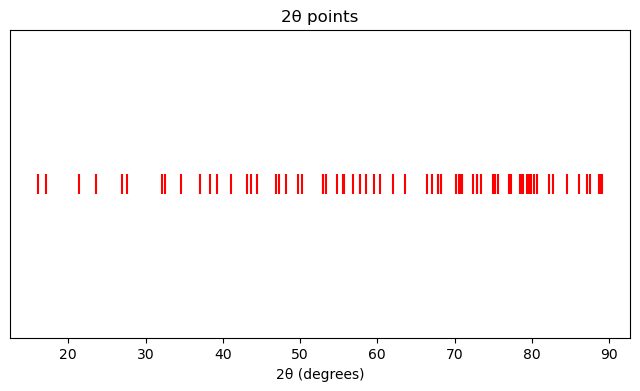

In [17]:
import matplotlib.pyplot as pl

plt.figure(figsize=(8,4))
plt.scatter(reflections, [1]*len(reflections), color='red', marker='|', s=200)  # vertical markers
plt.xlabel("2θ (degrees)")
plt.yticks([])  # no need for y-axis
plt.title("2θ points")
plt.show()

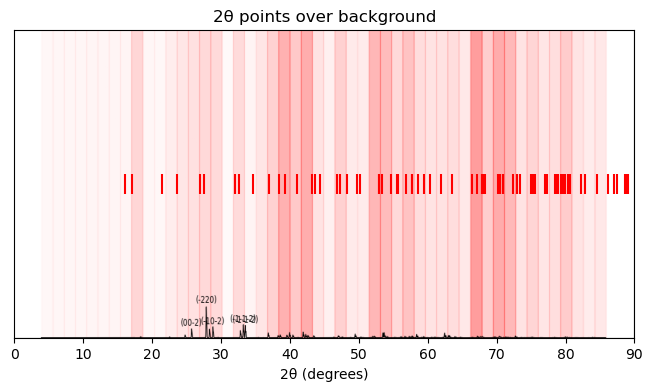

In [23]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Load your background image
img = mpimg.imread("media_images_attention_overlay_sample_85_copy.png")  # can be png, jpg, etc.

# Create figure and axis
fig, ax = plt.subplots(figsize=(8,4))

# Display the image as the background
ax.imshow(img, extent=[0, 90, 0, 1], aspect='auto')  

# Overlay 2theta points
ax.scatter(reflections, [0.5]*len(reflections), color='red', marker='|', s=200)  

ax.set_xlabel("2θ (degrees)")
ax.set_yticks([])
ax.set_title("2θ points over background")
plt.show()
